In [1]:
import pandas as pd

In [2]:
df = pd.read_csv("./data/train_starter_2000.csv")

In [3]:
df.head()

,id,text,label
0,1,Cipriani S.A. is an Italian hotel and leisure ...,0
1,3,"""Petit Beurre -- Butter Cookies\n\n1 cup (2 st...",1
2,23,"Serra was born in San Francisco, California to...",1
3,24,Medical image segmentation is inherently an am...,0
4,29,Introduction\n\nCASSOD-Net (Centralized Attent...,1


In [4]:
from sklearn.model_selection import train_test_split

X = df["text"]
y = df["label"]

X,y

(0       Cipriani S.A. is an Italian hotel and leisure ...
 1       "Petit Beurre -- Butter Cookies\n\n1 cup (2 st...
 2       Serra was born in San Francisco, California to...
 3       Medical image segmentation is inherently an am...
 4       Introduction\n\nCASSOD-Net (Centralized Attent...
                               ...                        
 1995    We propose variational reaction-diffusion syst...
 1996    When I see a bus on the road, it fills me with...
 1997    So as is customary for all my playthroughs for...
 1998    Lusaka, ZAMBIA (AP) — The government in this s...
 1999    3/4 cup whole almonds (see Notes)\nVegetable-o...
 Name: text, Length: 2000, dtype: str,
 0       0
 1       1
 2       1
 3       0
 4       1
        ..
 1995    1
 1996    1
 1997    0
 1998    1
 1999    0
 Name: label, Length: 2000, dtype: int64)

In [5]:
# Split data into train and test sets

RANDOM_SEED = 42
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=RANDOM_SEED, stratify=y)

X_train, X_test, y_train, y_test

(937     I don't think it's appropriate or ethical to i...
 959     Marcel Hug (born August 10, 1968) is a Swiss a...
 1015    The main aim of this paper is twofold. First w...
 1216    John Samuel Rowell (April 1, 1825 – October 21...
 1010    This film was nominated in 11 categories at th...
                               ...                        
 470     Ingredients:\n\n- 1/2 cup butter\n- 1 cup whit...
 921     So about 20 minutes after doing a delivery and...
 487     Asset-based lending is a type of lending that ...
 595     In this paper, we present a novel approach to ...
 1041    Pierson Fodé is an American actor and model. H...
 Name: text, Length: 1600, dtype: str,
 1501    6 tablespoons unsalted butter (3/4 stick)\n1 c...
 43      1 1/4 cups all purpose flour\n1 pinch salt\n1/...
 173     Ingredients:\n1 cup (2 sticks) butter, softene...
 952     Xóchitl Castañeda is the Founding Director of ...
 995     1 squash, weighing about 2lbs, chopped into ch...
                 

In [6]:
X_train.shape, y_train.shape

((1600,), (1600,))

Training time: 0.29 seconds
Test set results:
Accuracy: 0.8200
F1 score: 0.8085
ROC-AUC: 0.8922
Train set results:
Accuracy: 0.9956
F1 score: 0.9956
ROC-AUC: 0.9998


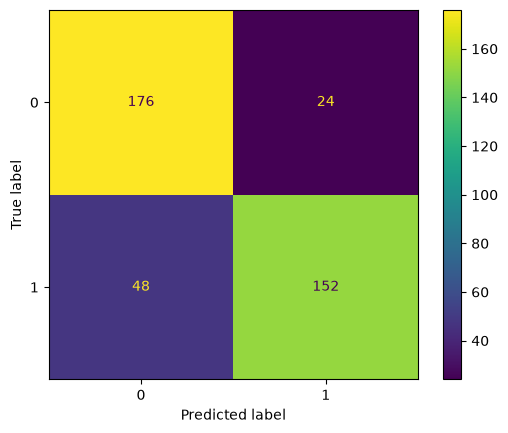

In [7]:
# try two approaches: tf-idf + logistic regression vs embedding + logistic regression

# 1) TF-IDF + logistic regression

import time

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    roc_auc_score,
)


pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            ngram_range=(1, 2),
            max_features=50000,
            sublinear_tf=True,
        ),
    ),
    (
        "classifier",
        LogisticRegression(
            random_state=RANDOM_SEED,
            C=1.0,
            max_iter=1000,
        ),
    ),
])

# report training time
start_time = time.time()
pipeline.fit(X_train, y_train)
training_time = time.time() - start_time
print(f"Training time: {training_time:.2f} seconds")

y_pred = pipeline.predict(X_test)
y_probability = pipeline.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm).plot()


# test auroc
accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_probability)

print("Test set results:")
print(f"Accuracy: {accuracy:.4f}")
print(f"F1 score: {f1:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")


# train auroc
y_train_pred = pipeline.predict(X_train)
y_train_probability = pipeline.predict_proba(X_train)[:, 1]

train_accuracy = accuracy_score(y_train, y_train_pred)
train_f1 = f1_score(y_train, y_train_pred)
train_roc_auc = roc_auc_score(y_train, y_train_probability)

print("Train set results:")
print(f"Accuracy: {train_accuracy:.4f}")
print(f"F1 score: {train_f1:.4f}")
print(f"ROC-AUC: {train_roc_auc:.4f}")

In [8]:
# perform grid search on tf-idf + logistic regression hyperparameter

from sklearn.model_selection import GridSearchCV

param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2), (1, 3)],
    "tfidf__max_features": [10000, 20000, 50000],
    "classifier__C": [0.01, 0.1, 1.0, 10.0],
}

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    scoring="roc_auc",
    n_jobs=-1,
    verbose=2,
)
grid_search.fit(X_train, y_train)

print(f"Best parameters: {grid_search.best_params_}")
print(f"Best cross-validated ROC-AUC: {grid_search.best_score_:.4f}")

# evaluate the best model on the test set
best_pipeline = grid_search.best_estimator_
y_pred = best_pipeline.predict(X_test)
y_probability = best_pipeline.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_probability)

print("Test set results for the best model:")
print(f"Accuracy: {accuracy:.4f}")
print(f"F1 score: {f1:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")

# evaluate the best model on the train set
y_train_pred = best_pipeline.predict(X_train)
y_train_probability = best_pipeline.predict_proba(X_train)[:, 1]

train_accuracy = accuracy_score(y_train, y_train_pred)
train_f1 = f1_score(y_train, y_train_pred)
train_roc_auc = roc_auc_score(y_train, y_train_probability)

print("Train set results for the best model:")
print(f"Accuracy: {train_accuracy:.4f}")
print(f"F1 score: {train_f1:.4f}")
print(f"ROC-AUC: {train_roc_auc:.4f}")


Fitting 5 folds for each of 36 candidates, totalling 180 fits


[CV] END classifier__C=0.01, tfidf__max_features=10000, tfidf__ngram_range=(1, 1); total time=   0.2s
[CV] END classifier__C=0.01, tfidf__max_features=10000, tfidf__ngram_range=(1, 1); total time=   0.2s
[CV] END classifier__C=0.01, tfidf__max_features=10000, tfidf__ngram_range=(1, 1); total time=   0.2s
[CV] END classifier__C=0.01, tfidf__max_features=10000, tfidf__ngram_range=(1, 1); total time=   0.3s
[CV] END classifier__C=0.01, tfidf__max_features=10000, tfidf__ngram_range=(1, 1); total time=   0.2s
[CV] END classifier__C=0.01, tfidf__max_features=10000, tfidf__ngram_range=(1, 2); total time=   0.7s
[CV] END classifier__C=0.01, tfidf__max_features=10000, tfidf__ngram_range=(1, 2); total time=   0.7s
[CV] END classifier__C=0.01, tfidf__max_features=10000, tfidf__ngram_range=(1, 2); total time=   0.7s
[CV] END classifier__C=0.01, tfidf__max_features=20000, tfidf__ngram_range=(1, 1); total time=   0.1s
[CV] END classifier__C=0.01, tfidf__max_features=10000, tfidf__ngram_range=(1, 2);

Training time: 54.67 seconds
Test set results:
Accuracy: 0.8100
F1 score: 0.8041
ROC-AUC: 0.8900
Train set results:
Accuracy: 0.8744
F1 score: 0.8702
ROC-AUC: 0.9500


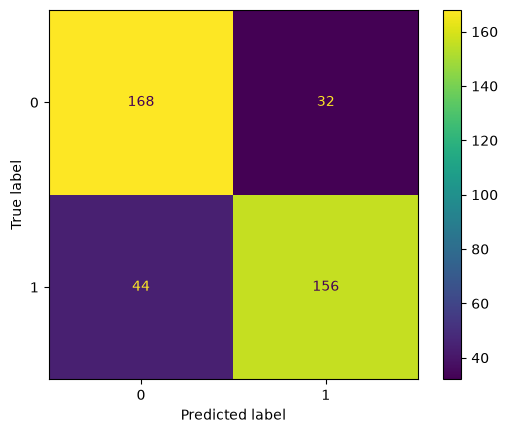

In [16]:
import time

import numpy as np
import ollama

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    roc_auc_score,
)


class OllamaEmbeddingTransformer(BaseEstimator, TransformerMixin):
    """Embed texts with a model served by the local Ollama daemon.

    Ollama answers a single /api/embed call with an error once the combined
    input gets too large (measured here: ~310 KB of text, i.e. roughly
    70k tokens, fails; 200 KB is fine). One batch of 32 short documents
    is ~40 KB, so there is plenty of headroom.
    Sending all 1600 training texts in one request therefore fails with
    "ResponseError: Post http://127.0.0.1:<port>/v1/tokenize ... connection
    reset by peer", so we embed in small batches instead.
    """

    def __init__(self, model="embeddinggemma-2:270m", batch_size=32):
        self.model = model
        self.batch_size = batch_size

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        texts = np.asarray(X, dtype=str).tolist()

        vectors = []
        for start in range(0, len(texts), self.batch_size):
            batch = texts[start : start + self.batch_size]
            response = ollama.embed(model=self.model, input=batch)
            vectors.extend(response["embeddings"])

        return np.asarray(vectors, dtype=np.float32)


pipeline = Pipeline([
    ("embedding", OllamaEmbeddingTransformer()),
    (
        "classifier",
        LogisticRegression(
            random_state=RANDOM_SEED,
            C=1.0,
            max_iter=1000,
        ),
    ),
])

# report training time
start_time = time.time()
pipeline.fit(X_train, y_train)
training_time = time.time() - start_time
print(f"Training time: {training_time:.2f} seconds")

y_pred = pipeline.predict(X_test)
y_probability = pipeline.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm).plot()

# test auroc
accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_probability)

print("Test set results:")
print(f"Accuracy: {accuracy:.4f}")
print(f"F1 score: {f1:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")

# train auroc
y_train_pred = pipeline.predict(X_train)
y_train_probability = pipeline.predict_proba(X_train)[:, 1]

train_accuracy = accuracy_score(y_train, y_train_pred)
train_f1 = f1_score(y_train, y_train_pred)
train_roc_auc = roc_auc_score(y_train, y_train_probability)

print("Train set results:")
print(f"Accuracy: {train_accuracy:.4f}")
print(f"F1 score: {train_f1:.4f}")
print(f"ROC-AUC: {train_roc_auc:.4f}")